In [1]:
%load_ext autoreload
%autoreload 2   

In [2]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning) 

In [11]:
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0, str(root))

from collections import OrderedDict
from pathlib import Path

import representation_spaces as rs
from data import GoEmotions
import part1
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools


## Data statistics

#TODO: write dataset description

#TODO: how to handle multi-class data points?

#TODO: merge dev and train for cross-validation?

In [4]:
ds = GoEmotions(drop_multi_labels=True)
ds.summary

,Total comments,Average n tokens,Median n tokens,Max tokens
train,36308.0,15.37,15.0,47.0
dev,4548.0,15.29,15.0,37.0
test,4590.0,15.26,15.0,37.0


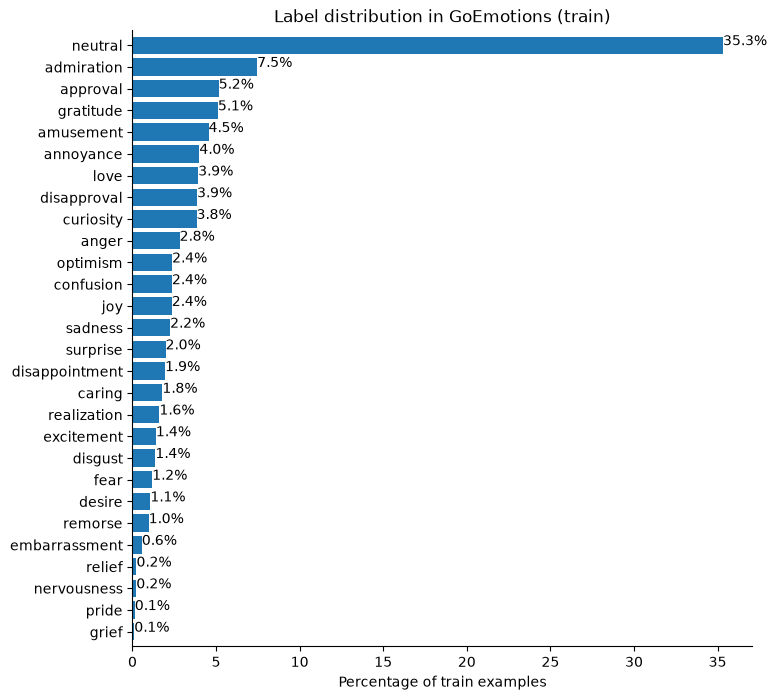

In [5]:
ds.plot_label_dist()

## Experiment

#TODO: description

In [6]:
from tokenizer import WordTokenizer

min_frequency = 1
tokenizer = WordTokenizer().train(ds.train["text"].tolist(), vocab_size=None, min_frequency=min_frequency)
token_indicator_encoder = rs.TokenIndicator(tokenizer)
bag_of_words_encoder = rs.BagOfWords(tokenizer)
tfidf_encoder = rs.Tfidf(tokenizer).fit(ds.train["text"].tolist())

my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []

for seed in my_seeds:
    my_cross_validation_sets.append(
        part1.experiment.cross_validation_split(
            pairs=list(zip(ds.train["text"], ds.train["label"])), 
            k=num_folds,
            seed=seed)
    )

results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True)

emotions_outcome_space = part1.clslib.NamedClasses(names=ds.emotions)

In [7]:
tokenizer.save(f"{results_folder}/word_tokenizer_vs_{len(tokenizer.get_vocab())}_mf_{min_frequency}.json")

In [8]:
configs = {
    'logistic_indicator-enc': {
        'encoder': token_indicator_encoder,
        'model_option': 'logistic',
        'extra_args':{
            'loglin_args': {
                'max_iter': 300,
            }
        }
    },
    'mlp_indicator-enc': {
        'encoder': token_indicator_encoder,
        'model_option': 'mlp',
        'extra_args':{
            'smlp_args': {
                'hidden_dim': 128, 
                'num_hidden_layers': 1,
                'dropout': 0.1, 
                'batch_size': 512, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 10,
                'device': 'cuda' if torch.cuda.is_available() else 'cpu',
            }
        }
    },
    'deeper_mlp_indicator-enc': {
        'encoder': token_indicator_encoder,
        'model_option': 'mlp',
        'extra_args':{
            'smlp_args': {
                'hidden_dim': 128, 
                'num_hidden_layers': 2,
                'dropout': 0.1, 
                'batch_size': 512, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 10,
                'device': 'cuda' if torch.cuda.is_available() else 'cpu',
            }
        }
    },
    'logistic_bag-of-words-enc': {
        'encoder': bag_of_words_encoder,
        'model_option': 'logistic',
        'extra_args':{
            'loglin_args': {
                'max_iter': 300,
            }
        }
    },
    'mlp_bag-of-words-enc': {
        'encoder': bag_of_words_encoder,
        'model_option': 'mlp',
        'extra_args':{
            'smlp_args': {
                'hidden_dim': 128, 
                'num_hidden_layers': 1,
                'dropout': 0.1, 
                'batch_size': 512, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 10,
                'device': 'cuda' if torch.cuda.is_available() else 'cpu',
            }
        }
    },
    'deeper_mlp_bag-of-words-enc': {
        'encoder': bag_of_words_encoder,
        'model_option': 'mlp',
        'extra_args':{
            'smlp_args': {
                'hidden_dim': 128, 
                'num_hidden_layers': 2,
                'dropout': 0.1, 
                'batch_size': 512, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 10,
                'device': 'cuda' if torch.cuda.is_available() else 'cpu',
            }
        }
    },
    'logistic_tfidf-enc': {
        'encoder': tfidf_encoder,
        'model_option': 'logistic',
        'extra_args':{
            'loglin_args': {
                'max_iter': 300,
            }
        }
    },
    'mlp_tfidf-enc': {
        'encoder': tfidf_encoder,
        'model_option': 'mlp',
        'extra_args':{
            'smlp_args': {
                'hidden_dim': 128, 
                'num_hidden_layers': 1,
                'dropout': 0.1, 
                'batch_size': 512, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 10,
                'device': 'cuda' if torch.cuda.is_available() else 'cpu',
            }
        }
    },
    'deeper_mlp_tfidf-enc': {
        'encoder': tfidf_encoder,
        'model_option': 'mlp',
        'extra_args':{
            'smlp_args': {
                'hidden_dim': 128, 
                'num_hidden_layers': 2,
                'dropout': 0.1, 
                'batch_size': 512, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 10,
                'device': 'cuda' if torch.cuda.is_available() else 'cpu',
            }
        }
    },
}

my_classifiers = OrderedDict()
for config in configs:
    my_classifiers[config] = []
    for run, seed in enumerate(my_seeds):
        run_folder = f"{results_folder}/{config}/seed-{seed}"
        my_classifiers[config].append(
            part1.experiment.cross_validation_experiment(
                data_splits=my_cross_validation_sets[run],
                outcome_space=emotions_outcome_space,
                encoder=configs[config]['encoder'],
                model_option=configs[config]['model_option'],
                save_to=run_folder,
                **configs[config]['extra_args'],
            )
        )

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 5.773 seconds
Dataloader done! Time taken: 0.101 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

/Users/ioanadumitrache/masters courses/nlp/nlp1-student/part1/smlp.py:87: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:923.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 01 | train loss: 2.8908 | train acc: 0.3305 | val loss: 2.6031 | val acc: 0.3675
Epoch 02 | train loss: 2.3679 | train acc: 0.4213 | val loss: 2.2154 | val acc: 0.4608
Epoch 03 | train loss: 1.8680 | train acc: 0.5199 | val loss: 1.8814 | val acc: 0.5178
Epoch 04 | train loss: 1.4591 | train acc: 0.6001 | val loss: 1.6998 | val acc: 0.5426
Epoch 05 | train loss: 1.1688 | train acc: 0.6718 | val loss: 1.6213 | val acc: 0.5549
Epoch 06 | train loss: 0.9655 | train acc: 0.7253 | val loss: 1.5918 | val acc: 0.5620
Epoch 07 | train loss: 0.8126 | train acc: 0.7713 | val loss: 1.5929 | val acc: 0.5660
Epoch 08 | train loss: 0.6966 | train acc: 0.8088 | val loss: 1.6120 | val acc: 0.5644
Epoch 09 | train loss: 0.6059 | train acc: 0.8337 | val loss: 1.6379 | val acc: 0.5592
Epoch 10 | train loss: 0.5301 | train acc: 0.8561 | val loss: 1.6670 | val acc: 0.5530
Training done! Time taken: 11.669 seconds
Transforming documents...
Document transformation done! Time taken: 6.012 seconds
Datalo

... (67 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 2.9377 | train acc: 0.3460 | val loss: 2.5849 | val acc: 0.3674
Epoch 02 | train loss: 2.5237 | train acc: 0.3498 | val loss: 2.4237 | val acc: 0.3741
Epoch 03 | train loss: 2.2179 | train acc: 0.3992 | val loss: 2.1483 | val acc: 0.4512
Epoch 04 | train loss: 1.8109 | train acc: 0.4997 | val loss: 1.9262 | val acc: 0.5032
Epoch 05 | train loss: 1.4720 | train acc: 0.5806 | val loss: 1.8633 | val acc: 0.5159
Epoch 06 | train loss: 1.2127 | train acc: 0.6578 | val loss: 1.8825 | val acc: 0.5203
Epoch 07 | train loss: 0.9969 | train acc: 0.7258 | val loss: 1.9220 | val acc: 0.5154
Epoch 08 | train loss: 0.8285 | train acc: 0.7761 | val loss: 2.0046 | val acc: 0.5072
Epoch 09 | train loss: 0.6974 | train acc: 0.8166 | val loss: 2.0936 | val acc: 0.4951
Epoch 10 | train loss: 0.5996 | train acc: 0.8430 | val loss: 2.2155 | val acc: 0.4970
Training done! Time taken: 11.227 seconds
Transforming documents...
Document transformation done! Time taken: 6.494 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 2.9219 | train acc: 0.3475 | val loss: 2.6181 | val acc: 0.3502
Epoch 02 | train loss: 2.5253 | train acc: 0.3539 | val loss: 2.4766 | val acc: 0.3502
Epoch 03 | train loss: 2.2329 | train acc: 0.3951 | val loss: 2.1879 | val acc: 0.4341
Epoch 04 | train loss: 1.8058 | train acc: 0.5021 | val loss: 1.9789 | val acc: 0.4911
Epoch 05 | train loss: 1.4794 | train acc: 0.5829 | val loss: 1.9307 | val acc: 0.5038
Epoch 06 | train loss: 1.2243 | train acc: 0.6620 | val loss: 1.9312 | val acc: 0.5003
Epoch 07 | train loss: 1.0107 | train acc: 0.7216 | val loss: 1.9874 | val acc: 0.5064
Epoch 08 | train loss: 0.8403 | train acc: 0.7742 | val loss: 2.0601 | val acc: 0.5023
Epoch 09 | train loss: 0.7016 | train acc: 0.8167 | val loss: 2.1408 | val acc: 0.4975
Epoch 10 | train loss: 0.5928 | train acc: 0.8430 | val loss: 2.2443 | val acc: 0.4919
Training done! Time taken: 11.849 seconds


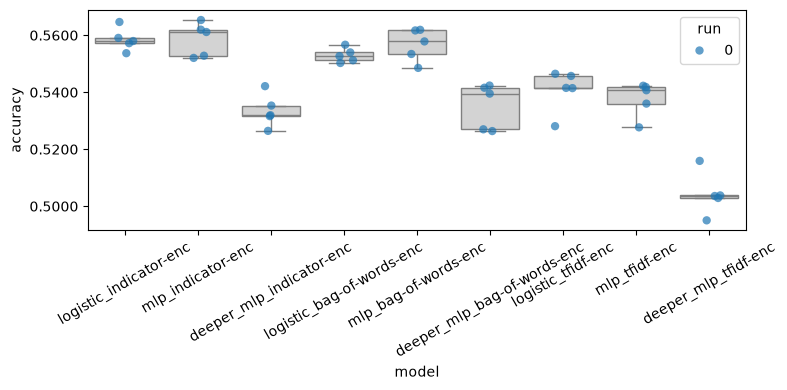

In [9]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

In [12]:
def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data['accuracies'].values()) for run_data in data[sys_name]])

rope = 0.005
names = list(my_classifiers.keys())          # all nine configs
scores = {n: get_all_measurements_for(my_classifiers, n).flatten() for n in names}

rows = []
p_win = pd.DataFrame(np.nan, index=names, columns=names)   # P(row beats column)

for a, b in itertools.combinations(names, 2):
    posterior = part1.analysis.BenavoliCorrelatedT(
        scores[a],        # shape [num_runs * num_folds]
        scores[b],
        names=[a, b],
    )
    p_a, p_tie, p_b = posterior.probs(rope)
    rows.append({
        "A": a, "B": b,
        "P(A wins)": p_a, "P(Tie)": p_tie, "P(B wins)": p_b,
        "effect_size": posterior.effect_size,
    })
    p_win.loc[a, b] = p_a
    p_win.loc[b, a] = p_b

results_df = pd.DataFrame(rows)
print(results_df.round(4).to_string(index=False))

                          A                           B  P(A wins)  P(Tie)  P(B wins)  effect_size
     logistic_indicator-enc           mlp_indicator-enc     0.0396  0.9150     0.0454       0.0627
     logistic_indicator-enc    deeper_mlp_indicator-enc     0.9975  0.0019     0.0005      -7.0279
     logistic_indicator-enc   logistic_bag-of-words-enc     0.6671  0.3325     0.0005      -4.5943
     logistic_indicator-enc        mlp_bag-of-words-enc     0.1779  0.7790     0.0432      -0.6103
     logistic_indicator-enc deeper_mlp_bag-of-words-enc     0.9957  0.0034     0.0009      -6.1324
     logistic_indicator-enc          logistic_tfidf-enc     0.9927  0.0064     0.0009      -5.7158
     logistic_indicator-enc               mlp_tfidf-enc     0.9971  0.0024     0.0005      -7.1032
     logistic_indicator-enc        deeper_mlp_tfidf-enc     1.0000  0.0000     0.0000     -22.3228
          mlp_indicator-enc    deeper_mlp_indicator-enc     0.9986  0.0011     0.0003      -8.1817
          

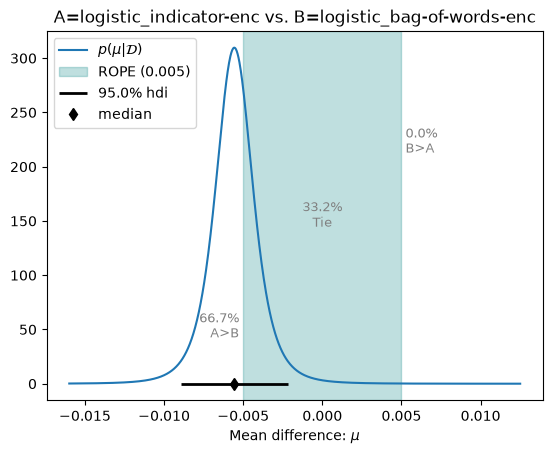

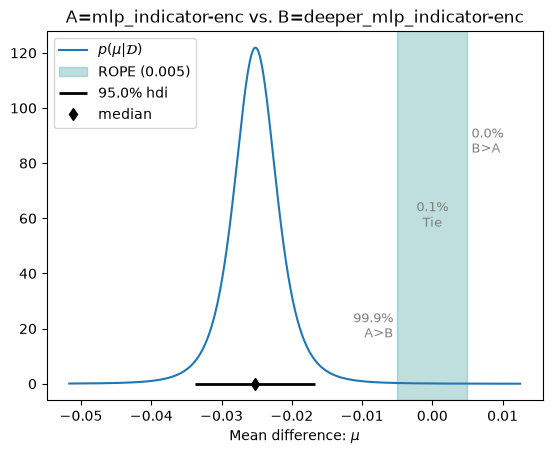

In [16]:
def plot_pair(a, b):
    return part1.analysis.BenavoliCorrelatedT(
        scores[a], scores[b], names=[a, b]
    ).plot(rope)

_ = plot_pair('logistic_indicator-enc', 'logistic_bag-of-words-enc')
_ = plot_pair('mlp_indicator-enc', 'deeper_mlp_indicator-enc')

In [17]:
from sklearn.metrics import accuracy_score, f1_score
import loglin, smlp        # if this fails, try: from part1 import loglin, smlp

test_texts = ds.test["text"].tolist()
y_test = np.array([int(l) for l in ds.test["label"]])

def fold_probs(config, model_path, texts):
    enc = configs[config]['encoder']
    if configs[config]['model_option'] == 'logistic':
        model = loglin.load(model_path)
        return loglin.predict_probs(texts, model, enc)
    model = smlp.load(model_path)
    return smlp.predict_probs(texts, model, enc, batch_size=512)

test_probs, test_preds, test_rows = {}, {}, []
for name in configs:
    paths = [p for run in my_classifiers[name] for p in run['models'].values()]   # all seeds x folds
    probs = np.mean([fold_probs(name, p, test_texts) for p in paths], axis=0)    # average over fold models
    test_probs[name] = probs
    test_preds[name] = probs.argmax(axis=1)
    test_rows.append({
        "system": name,
        "accuracy": accuracy_score(y_test, test_preds[name]),
        "macro_f1": f1_score(y_test, test_preds[name], average="macro"),
    })

test_df = pd.DataFrame(test_rows).sort_values("accuracy", ascending=False)
test_df.round(4)

,system,accuracy,macro_f1
0,logistic_indicator-enc,0.5721,0.3870
1,mlp_indicator-enc,0.5697,0.3636
4,mlp_bag-of-words-enc,0.5693,0.3681
3,logistic_bag-of-words-enc,0.5673,0.3816
7,mlp_tfidf-enc,0.5514,0.3543
2,deeper_mlp_indicator-enc,0.5508,0.2805
5,deeper_mlp_bag-of-words-enc,0.5490,0.2982
6,logistic_tfidf-enc,0.5403,0.3108
8,deeper_mlp_tfidf-enc,0.5283,0.2463
